# 03 — Small CNN on log-mel spectrograms

The baseline (notebook 02) reached **0.188 balanced accuracy** on the test instruments (chance 0.10). Its main
weakness by design: the mean/std summary throws away **the order of events in time**. A CNN sees the whole
time × frequency image, so it can in principle use the shape of the envelope (bright attack then dark sustain,
fast vs slow decay, inharmonic partials of a struck bar).

It has the same data problem, though: very few instruments per family. This notebook explains every choice made
in [`src/features.py`](../src/features.py), [`src/model.py`](../src/model.py) and [`src/train.py`](../src/train.py),
and shows the training run. **The test set is not used here**; it is evaluated once, in notebook 04.

The model is trained by a script, not in this notebook (`python -m src.train`, ~30 min on a laptop CPU). This
notebook reads the saved checkpoint and training history.

In [1]:
import json
import sys

import librosa.display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

sys.path.insert(0, "..")
from src.dataset import ROOT, SR, load_notes, with_validation
from src.features import HOP, N_FRAMES, N_MELS, load_logmel
from src.model import LogMelCNN, n_parameters
from src.train import FAMILIES, HISTORY, band_stats, balanced_accuracy, class_weights, load_checkpoint, predict_logits, spec_augment

notes = with_validation(load_notes())
history = json.loads(HISTORY.read_text())
config = history["config"]
FRAMES = config["frames"]
fit, val = notes[notes["split"] == "train"], notes[notes["split"] == "val"]
print(f"fit: {len(fit)} notes, {fit['instrument'].nunique()} instruments | "
      f"val: {len(val)} notes, {val['instrument'].nunique()} instruments | test (not used here): {(notes['split'] == 'test').sum()} notes")

fit: 11291 notes, 36 instruments | val: 2048 notes, 7 instruments | test (not used here): 3435 notes


## 1. Input: the log-mel spectrogram from notebook 00

Exactly the same settings as notebook 00: `n_fft=1024` (64 ms window), `hop=256` (16 ms), 128 mel bands, 16 kHz.
The power is converted to dB **relative to the loudest bin of each note** (`ref=np.max`) and floored at −80 dB, so
every note has its peak at 0 dB.

That last point differs from the MFCC baseline, whose coefficient 0 carries the absolute level. Here the overall level
(velocity, recording gain) is gone. I think that is the right default: how loud a note was recorded says nothing
about the family, and it is an easy shortcut for a model to latch onto.

Computing it for 16,774 notes takes ~1 min in parallel (`python -m src.features logmel`). The result is cached as
one **float16** array of 16,774 × 128 × 251 (1.1 GB). float16 has ~3 significant digits; on values in [−80, 0] dB the
rounding error is ≤ 0.03 dB (checked against a fresh computation), far below anything audible or learnable.

### Decision: only the first 2.0 s (126 of 251 frames)

Budget: ~40 min of CPU training in total. I first ran **one epoch on the full 4 s: 224 s** (205 s training + 19 s
validation). Up to 18 epochs at that speed would take ~67 min; within the budget there would be room for only ~9 epochs,
so the clock rather than early stopping would decide when training ends.

Options: fewer mel bands, fewer epochs, or a shorter crop. I kept all 128 mel bands, because frequency detail *is* the
timbre signal, and cut time instead: cost scales roughly linearly with the number of frames (measured: 0.39 s per batch
at 126 frames vs 0.75 s at 251, model compute only).

**What actually happened, honestly.** Before the real run I also made the cropped array *contiguous* in memory (a slice
of the cache is not, and indexing random batches out of it is slow). The first real epoch at 126 frames took 80 s, faster
than the ~110 s I had extrapolated, so part of the 224 s was the data pipeline, not the model. But later epochs slowed
down to 130–150 s (most likely the laptop throttling under sustained load), so timings on this machine vary by ±50%
and any extrapolation is rough. Either way, 18 full-length epochs would not have fitted in the budget, so the crop decision
stands. Lesson: time the data pipeline separately from the model before deciding what to cut.

What the crop keeps and loses: NSynth notes are held for 3 s and then released, so the first 2 s contain the attack and
the start of the sustain or decay. The crop loses the **release** (how the note stops, e.g. an organ cuts off
abruptly), which is a real timbre cue. The cell below measures how much of the signal actually lives after 2 s.

In [2]:
X_fit_full = load_logmel(fit)
active = X_fit_full.max(axis=1) > -60  # (notes, frames): frame within 60 dB of the note's peak
split_at = FRAMES
share = pd.DataFrame({
    "family": fit["family"].to_numpy(),
    "active frames, first 2 s": active[:, :split_at].mean(axis=1),
    "active frames, last 2 s": active[:, split_at:].mean(axis=1),
}).groupby("family").mean()
print(f"frames kept: {FRAMES} of {N_FRAMES} = first {FRAMES * HOP / SR:.2f} s")
share.round(2)

frames kept: 126 of 251 = first 2.02 s


,"active frames, first 2 s","active frames, last 2 s"
family,,
bass,0.97,0.59
brass,1.00,0.76
flute,1.00,0.84
guitar,0.90,0.49
keyboard,0.87,0.48
mallet,0.85,0.45
organ,1.00,0.74
reed,0.71,0.35
string,0.93,0.62


I expected the last 2 s to be nearly silent for decaying families. **The data says otherwise:** in every family, 35–84%
of the frames in the last 2 s are still within 60 dB of the note's peak (60 dB is a generous threshold; much of this is
quiet decay tails and room sound). So the crop does throw away real signal: the late part of the decay, the end of the
sustain, and the release. What it keeps is the part where the families differ most visibly in notebook 00 (attack,
early decay, harmonic pattern), but this is a cost, not a free lunch. It is the first thing I would revert with more compute.

## 2. Validation: instruments taken out of the training side

Early stopping needs a validation set, and the test set must not be used for it. Following the same logic as the
train/test split, validation is **grouped by instrument**: random note-level validation would contain near-copies of
training notes and would reward memorising instruments (the 0.60 vs 0.19 gap of notebook 02).

Rule (`make_val_split`, seed 0): one random training instrument per family moves to validation, **but only if the family
has at least 3 training instruments**, so at least 2 remain for fitting.

In [3]:
inst = notes.groupby("instrument").agg(family=("family", "first"), source=("source", "first"),
                                       split=("split", "first"), notes=("note", "size")).reset_index()
table = inst[inst["split"] != "test"].groupby("family").agg(
    fit_instruments=("split", lambda s: (s == "train").sum()),
    val_instrument=("instrument", lambda s: ", ".join(s[inst.loc[s.index, "split"] == "val"]) or "-"),
)
table

,fit_instruments,val_instrument
family,,
bass,8,bass_synthetic_098
brass,3,brass_acoustic_016
flute,1,-
guitar,5,guitar_acoustic_030
keyboard,6,keyboard_electronic_001
mallet,2,-
organ,4,organ_electronic_028
reed,2,reed_acoustic_018
string,4,string_acoustic_012


- **7 families have a validation instrument** (2,048 notes); fitting uses the remaining **36 instruments** (11,291 notes).
- **Flute and vocal** have a single training instrument; **mallet** has two. Taking one away would leave nothing (or one
  instrument) to learn the family from, so they keep all theirs and **are absent from validation**.

Consequences to keep in mind:
1. **Validation balanced accuracy averages over 7 families, not 10.** It excludes flute and vocal, which are near zero on
   test by construction (acoustic in train, synthetic in test), so validation numbers will look *better* than test.
   It is a tool to pick an epoch, not an estimate of the test score.
2. **The CNN sees fewer instruments than the baseline did** (36 vs 43). For a fair comparison, notebook 04 also reports the
   baseline refitted on the same 36.
3. Validation, like test, is one instrument per family, so it is noisy. Choosing *one* number (the epoch) on it is fine;
   tuning many hyperparameters on it would overfit it.

## 3. Normalisation per mel band, from the fit instruments only

Each mel band is standardised with its own mean and standard deviation, computed over **all frames of all fit notes**
(never validation or test). Why per band: low bands are on average much louder than the top ones. Without this, the first
convolution would see inputs whose scale depends on height in the image. Why only on fit notes: the statistics are part
of the model. Computing them on test notes would let information about the test instruments into training. With
one instrument per family in test it is a small leak, but it is free to avoid.

After normalisation, 0 means "the average level of this band in training", which is also the value SpecAugment fills
masks with (section 5).

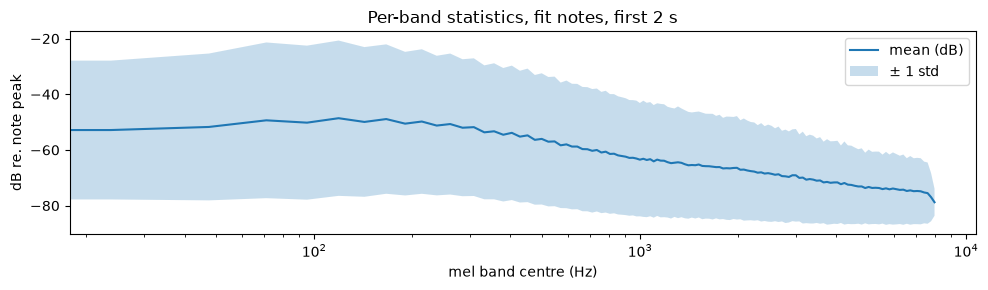

In [4]:
X_fit = np.ascontiguousarray(X_fit_full[:, :, :FRAMES])
del X_fit_full
mean, std = band_stats(X_fit)
ckpt_model, ckpt = load_checkpoint()
assert np.allclose(mean, ckpt["mean"]) and np.allclose(std, ckpt["std"])  # same statistics the model was trained with

mel_hz = librosa.mel_frequencies(n_mels=N_MELS, fmax=SR / 2)
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(mel_hz, mean, label="mean (dB)")
ax.fill_between(mel_hz, mean - std, mean + std, alpha=0.25, label="± 1 std")
ax.set(xscale="log", xlabel="mel band centre (Hz)", ylabel="dB re. note peak", title="Per-band statistics, fit notes, first 2 s")
ax.legend()
plt.tight_layout()

## 4. Class weights (same as the baseline)

Bass has ~25× more fit notes than vocal (2,601 vs 105). The loss is a cross-entropy where each family is weighted by
`n_notes / (n_families × n_notes_in_family)`, the same formula as scikit-learn's `class_weight="balanced"` used
in the baseline. So both models are pushed the same way towards balanced recall, and comparing balanced accuracy
between them is fair.

In [5]:
y_fit = fit["family"].map(FAMILIES.index).to_numpy(copy=True)
pd.DataFrame({"fit notes": np.bincount(y_fit, minlength=10), "weight": class_weights(y_fit)}, index=FAMILIES).round(2)

,fit notes,weight
bass,2601,0.43
brass,680,1.66
flute,210,5.38
guitar,2090,0.54
keyboard,2290,0.49
mallet,645,1.75
organ,1355,0.83
reed,565,2.00
string,750,1.51
vocal,105,10.75


## 5. Augmentation: SpecAugment, and why not pitch shift

**SpecAugment** (Park et al., 2019), masking part only: during training each spectrogram gets 2 frequency masks
(up to 16 mel bands each) and 2 time masks (up to 25 frames ≈ 0.4 s each), set to 0 = the band's training mean.
Validation and test inputs are never masked. The goal is to stop the network from relying on one narrow detail
(one band, one instant) that may be specific to a training instrument. It works directly on the cached spectrograms,
so it costs nothing.

**Pitch shifting is deliberately not used.** Shifting pitch by resampling or a phase vocoder moves *the whole spectrum*,
including the **formants**: the resonances fixed by the instrument's body (the bore of a clarinet, the body of a violin),
which stay roughly in place when a real instrument plays a higher note. A pitch-shifted cello is not "a cello playing
higher", it is a cello that has been shrunk. The "chipmunk" effect on voices is the same thing. Since timbre (largely
the formant envelope) *is* the class signal here, this augmentation would create notes with the wrong timbre and the right
label. It would also add little: NSynth already records every instrument at up to 88 real pitches, with correct formants.

A frequency *mask* also touches the spectrum, but it only hides information; it never creates a fake timbre.

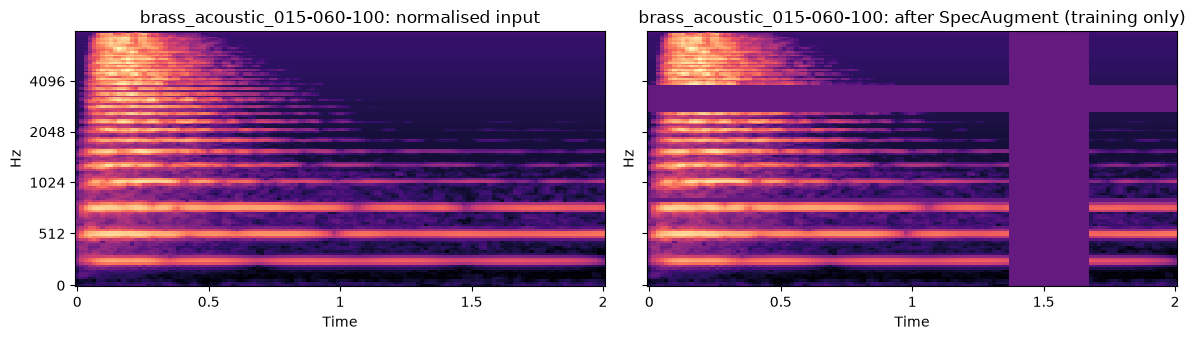

In [6]:
torch.manual_seed(1)
example = int(np.flatnonzero(fit["note"].to_numpy() == "brass_acoustic_015-060-100")[0])  # the brass note of notebook 00
x =(torch.from_numpy(X_fit[example : example + 1]).float() - torch.from_numpy(mean)[:, None]) / torch.from_numpy(std)[:, None]
x = x[:, None]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True)
for ax, img, title in [(axes[0], x, "normalised input"), (axes[1], spec_augment(x), "after SpecAugment (training only)")]:
    librosa.display.specshow(img[0, 0].numpy(), sr=SR, hop_length=HOP, x_axis="time", y_axis="mel", ax=ax, cmap="magma")
    ax.set(title=f"{fit['note'].iloc[example]}: {title}")
plt.tight_layout()

## 6. The model

Four blocks of **Conv 3×3 → BatchNorm → ReLU → MaxPool 2×2** (16, 32, 64, 128 channels), then **global average pooling**
over frequency and time, **dropout 0.3**, and one **Linear** layer to 10 logits.

- **Small on purpose (~99k parameters).** The limit is the number of instruments (36), not the number of notes: 11,291
  notes are really 36 "examples" of how families differ. A bigger network would memorise the 36 instruments faster.
- **BatchNorm** keeps the scale of activations stable, which makes a fixed learning rate (Adam, 1e-3) work without tuning.
- **Global average pooling** makes the output independent of the input length and keeps the head tiny (128 → 10).
  Its cost is that the final features are averaged over frequency too, so absolute frequency position survives only
  indirectly (through what each channel has learned to detect, and padding at the edges). Worth remembering in error analysis.
- **Receptive field** after 4 blocks: each final unit sees ~46 mel bands × ~46 frames (~0.7 s), enough for an attack and
  the spacing of several harmonics.

In [7]:
print(ckpt_model)
print(f"{n_parameters(ckpt_model):,} parameters; input (batch, 1, {N_MELS}, {FRAMES})")

LogMelCNN(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (5): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU(inplace=True)
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (9): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU(inplace=True)
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padd

## 7. Training and early stopping

- Adam, learning rate 1e-3, batch 64, weighted cross-entropy, SpecAugment on every training batch.
- After every epoch, **balanced accuracy on the validation instruments** is measured. The checkpoint is saved whenever it
  improves; training stops after 5 epochs without improvement, or at 18 epochs, or when another epoch would exceed a 35 min
  wall-clock budget (the 1-epoch timing run used the other ~4 min).
- The metric for early stopping is the same as the final metric (balanced accuracy), not the validation loss: the loss
  also rewards being *confident*, and with so few instruments confidence and correctness drift apart quickly.
- Nothing is tuned beyond this: no learning-rate search, no architecture search. With one validation instrument per family,
  a search would mostly fit the noise of those 7 instruments.

### My prediction, recorded before the final training run

Asked on 2026-11-10, after the 1-epoch timing run (validation balanced accuracy 0.197 on 7 families) and before the
final training: *"What balanced accuracy do you predict on the test set, and why?"* My answer, verbatim:

> Range 0.18–0.30, best guess ~0.23. The CNN should gain over the MFCC baseline because it sees how the
> sound evolves over time (attack/decay), which mean/std throws away — I expect fewer mallet↔keyboard and
> reed↔brass errors. But the gain should be small: the baseline’s problem was generalizing to unseen
> instruments, and now there are fewer training instruments (36 vs 43) and a model with more capacity to
> memorize them. Flute and vocal stay near zero by construction (acoustic in train, synthetic in test).
> I wouldn’t be surprised if it lands at or below the baseline.

Notebook 04 compares this with the actual result.

## 8. The training run

best val balanced accuracy 0.584 at epoch 6; checkpoint models\cnn_logmel.pt; 24.1 min
total time: 24.1 min (132 s per epoch)


,train_loss,train_acc,val_loss,val_bacc,sec_train,sec_total
epoch,,,,,,
1,1.528,0.373,2.026,0.493,73.983,79.614
2,0.943,0.598,1.580,0.424,99.984,107.304
3,0.679,0.710,1.929,0.523,105.968,115.245
4,0.545,0.774,1.428,0.555,126.582,137.961
5,0.448,0.810,1.753,0.551,127.378,136.234
6,0.364,0.841,2.071,0.584,134.583,145.698
7,0.330,0.851,1.883,0.552,139.411,151.347
8,0.283,0.868,2.271,0.483,145.902,156.130
9,0.248,0.886,2.091,0.553,121.626,131.672


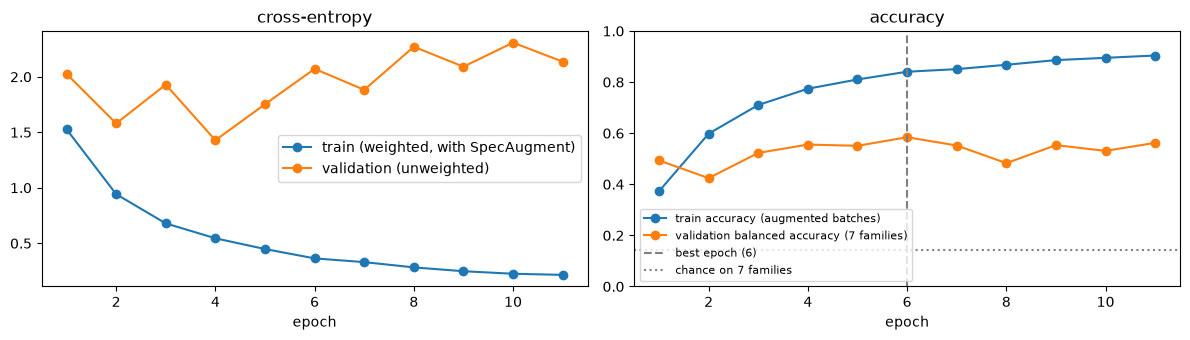

In [8]:
h = pd.DataFrame(history["history"]).set_index("epoch")
best = history["best_epoch"]
print((ROOT / "reports" / "cnn_train.log").read_text().splitlines()[-1])
print(f"total time: {h['sec_total'].sum() / 60:.1f} min ({h['sec_total'].mean():.0f} s per epoch)")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].plot(h.index, h["train_loss"], "o-", label="train (weighted, with SpecAugment)")
axes[0].plot(h.index, h["val_loss"], "o-", label="validation (unweighted)")
axes[0].set(title="cross-entropy", xlabel="epoch")
axes[0].legend()
axes[1].plot(h.index, h["train_acc"], "o-", label="train accuracy (augmented batches)")
axes[1].plot(h.index, h["val_bacc"], "o-", label="validation balanced accuracy (7 families)")
axes[1].axvline(best, color="gray", ls="--", label=f"best epoch ({best})")
axes[1].axhline(1 / 7, color="gray", ls=":", label="chance on 7 families")
axes[1].set(title="accuracy", xlabel="epoch", ylim=(0, 1))
axes[1].legend(fontsize=8)
plt.tight_layout()
h.round(3)

In [9]:
X_val = np.ascontiguousarray(load_logmel(val)[:, :, :FRAMES])
y_val = val["family"].map(FAMILIES.index).to_numpy(copy=True)
val_pred = predict_logits(ckpt_model, X_val, ckpt["mean"], ckpt["std"]).argmax(1)
print(f"best checkpoint: epoch {ckpt['epoch']}, validation balanced accuracy {balanced_accuracy(y_val, val_pred):.3f}")
pd.DataFrame({
    "val instrument": val.groupby("family")["instrument"].first(),
    "recall": pd.Series(val_pred == y_val).groupby(val["family"].to_numpy()).mean(),
    "most common prediction": pd.Series(np.array(FAMILIES)[val_pred]).groupby(val["family"].to_numpy()).agg(lambda s: s.value_counts().index[0]),
}).round(2)

best checkpoint: epoch 6, validation balanced accuracy 0.584


,val instrument,recall,most common prediction
bass,bass_synthetic_098,0.74,bass
brass,brass_acoustic_016,0.32,reed
guitar,guitar_acoustic_030,0.31,bass
keyboard,keyboard_electronic_001,0.91,keyboard
organ,organ_electronic_028,0.12,reed
reed,reed_acoustic_018,0.85,reed
string,string_acoustic_012,0.85,string


### Reading the training run

- **Validation balanced accuracy peaked at 0.584 at epoch 6** (chance on 7 families: 0.14). Early stopping ended the run
  after epoch 11 (5 epochs without improvement), in 24 min; the timing run had used ~4 min, so the total was ~28 of the
  ~40 min budget.
- **The model overfits the training instruments from about epoch 4 on.** Training accuracy keeps climbing (0.77 → 0.90,
  even on augmented batches) while validation loss goes *up* (1.43 at epoch 4 → 2.1–2.3) and validation balanced accuracy
  wanders between 0.48 and 0.58. Rising validation loss with flat accuracy means the model becomes *confidently wrong* on
  new instruments. This is the reason to stop on balanced accuracy rather than on loss: stopping on loss would have chosen
  epoch 4.
- **The best epoch is partly luck.** Validation balanced accuracy jumps by ±0.05 from one epoch to the next (0.55 → 0.58
  → 0.55 → 0.48). With one instrument per family, the difference between epoch 4 (0.555) and epoch 6 (0.584) is within that
  noise. Early stopping still did its job: it avoided the clearly worse late epochs.
- **Per family on validation** the picture is uneven: keyboard (0.91), reed and string (0.85) and bass (0.74) are recognised;
  brass (0.32, mostly called reed), guitar (0.31, mostly called bass) and organ (0.12, mostly called reed) are not. Brass ↔
  reed is the same "sustained wind" confusion the baseline made.
- **0.584 is not an estimate of the test score.** Validation excludes flute and vocal (near zero on test by construction) and
  the epoch was chosen on it, so it is optimistic twice over. The test set is evaluated once, in notebook 04.

### Takeaways

- The pipeline works end to end on CPU: cached log-mels, per-band normalisation from fit notes only, grouped validation,
  weighted loss, SpecAugment, early stopping on the final metric.
- The main problem is the same as for the baseline: **few instruments per family**. A 99k-parameter CNN memorises 36
  instruments in a handful of epochs; augmentation slows that down but does not create new instruments.
- Choices that cost something and that I would revisit with more compute: the 2 s crop, no retraining on fit + validation
  instruments, a single training seed.